In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,mean_squared_error
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import plotly.express as px
from sklearn.preprocessing import LabelEncoder
sns.set()

plt.style.use('ggplot')

In [2]:
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [3]:
import cv2
import skimage
import skimage.segmentation
import os, shutil
import random
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model,load_model
from tensorflow.keras.layers import Input, Dense, Flatten, MaxPooling2D,Conv2D, Dropout
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.optimizers import Adam,SGD, RMSprop
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils import shuffle
from tensorflow.keras.layers import GlobalAveragePooling2D

# Brain Tumor Classification from MRI Scans
Fine-tuning VGG19 with transfer learning to classify brain tumors. Data augmentation and early stopping are used to control overfitting. Evaluated with precision, recall, and AUC-ROC.

# Brain Tumor Classification

## Kaggle part

In [4]:
!pip install kaggle

In [5]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [6]:
!kaggle datasets download -d ahmedhamada0/brain-tumor-detection

Dataset URL: https://www.kaggle.com/datasets/ahmedhamada0/brain-tumor-detection
License(s): copyright-authors
100% 84.0M/84.0M [00:06<00:00, 13.6MB/s]



In [7]:
from zipfile import ZipFile
dataset = '/content/brain-tumor-detection.zip'

with ZipFile(dataset,'r') as zip:
  zip.extractall()
  print('The dataset is extracted')

The dataset is extracted


In [8]:
!ls

Br35H-Mask-RCNN  brain-tumor-detection.zip  no	pred  sample_data  yes


## rename images

In [9]:
folder = '/content/yes'
print(os.listdir(folder))

['y994.jpg', 'y343.jpg', 'y1077.jpg', 'y1225.jpg', 'y1404.jpg', 'y90.jpg', 'y575.jpg', 'y624.jpg', 'y374.jpg', 'y141.jpg', 'y335.jpg', 'y595.jpg', 'y590.jpg', 'y581.jpg', 'y837.jpg', 'y730.jpg', 'y1479.jpg', 'y1120.jpg', 'y656.jpg', 'y1140.jpg', 'y1223.jpg', 'y690.jpg', 'y279.jpg', 'y513.jpg', 'y49.jpg', 'y986.jpg', 'y1149.jpg', 'y711.jpg', 'y378.jpg', 'y12.jpg', 'y1473.jpg', 'y1398.jpg', 'y880.jpg', 'y1418.jpg', 'y1420.jpg', 'y440.jpg', 'y1188.jpg', 'y280.jpg', 'y510.jpg', 'y973.jpg', 'y1358.jpg', 'y331.jpg', 'y432.jpg', 'y1347.jpg', 'y843.jpg', 'y483.jpg', 'y1406.jpg', 'y871.jpg', 'y130.jpg', 'y1143.jpg', 'y32.jpg', 'y878.jpg', 'y903.jpg', 'y875.jpg', 'y757.jpg', 'y349.jpg', 'y42.jpg', 'y318.jpg', 'y526.jpg', 'y1138.jpg', 'y522.jpg', 'y1456.jpg', 'y775.jpg', 'y646.jpg', 'y951.jpg', 'y471.jpg', 'y564.jpg', 'y19.jpg', 'y89.jpg', 'y1074.jpg', 'y914.jpg', 'y1166.jpg', 'y1308.jpg', 'y829.jpg', 'y633.jpg', 'y475.jpg', 'y1240.jpg', 'y358.jpg', 'y317.jpg', 'y76.jpg', 'y748.jpg', 'y1067.jpg',

In [10]:
# rename images
folder = '/content/yes'
count=1
for filename in os.listdir(folder):
    source = os.path.join(folder, filename)
    destination = os.path.join(folder, "Y_" + str(count) + ".jpg")
    os.rename(source, destination)
    count+=1
print("All files are renamed in the yes dir.")

All files are renamed in the yes dir.


In [11]:
print(source)

/content/yes/y617.jpg


In [12]:
folder = '/content/no'
count=1
for filename in os.listdir(folder):
    source = os.path.join(folder, filename)
    destination = os.path.join(folder, "N_" + str(count) + ".jpg")
    os.rename(source, destination)
    count+=1
print("All files are renamed in the yes dir.")

All files are renamed in the yes dir.


## EDA

In [13]:
# os.listdir : returns the names of the entires in the folder
list_y = os.listdir("/content/yes")
yes_number = len(list_y)
print(f"number of images in Yes folder {yes_number}")

list_n = os.listdir("/content/no")
no_number =  len(list_n)
print(f"number of images in No folder {no_number}")

number of images in Yes folder 1500
number of images in No folder 1500


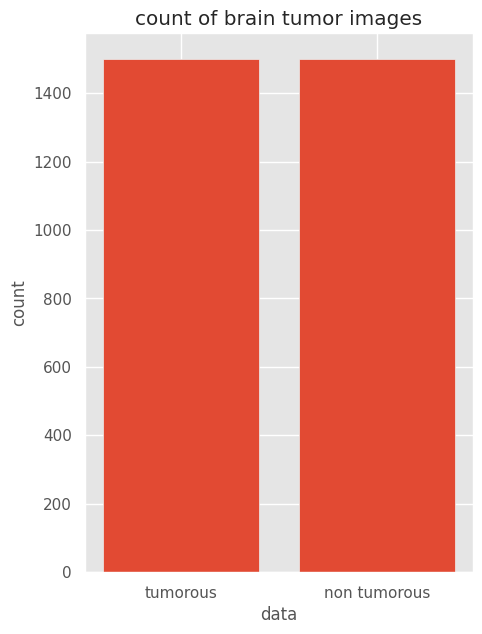

In [14]:
data={"tumorous":yes_number, "non tumorous": no_number}
typx= data.keys()
values = data.values()
plt.figure(figsize=(5,7))

plt.bar(typx,values)
plt.xlabel("data")
plt.ylabel("count")
plt.title("count of brain tumor images")
plt.show()

data agumentation

In [15]:
def timing(sec_elapsed):
  h = int(sec_elapsed /(60*60))
  m = int(sec_elapsed %(60*60/60))
  s = sec_elapsed % 60
  return f"{h}:{m}:{s}"
# how log it take to make images

In [16]:
def agumented_data(file_dir,n_generated_samples, save_to_dir):
  data_gen = ImageDataGenerator(rotation_range=20,
                                width_shift_range=0.3,
                                height_shift_range=0.3,
                                shear_range=0.3,
                                brightness_range=(0.3, 1.0),
                                horizontal_flip=True,
                                vertical_flip=True,
                                fill_mode='nearest')
  for filename in os.listdir(file_dir):
    image = cv2.imread(file_dir + '/' + filename)
    image = image.reshape((1,)+image.shape)
    save_prefix = 'aug_' + filename[:-4]
    i=0
    for batch in data_gen.flow(x=image, batch_size = 1, save_to_dir=save_to_dir, save_prefix=save_prefix, save_format="jpg" ):
      i+=1
      if i >n_generated_samples:
        break
# n_generated_samples : number of samples per image

In [17]:
import time
start_time = time.time()

os.makedirs('augmented_data/yes', exist_ok=True)
os.makedirs('augmented_data/no', exist_ok=True)

yes_path = '/content/yes'
no_path = '/content/no'
augmented_data_path = 'augmented_data/'

agumented_data(file_dir = yes_path, n_generated_samples=5, save_to_dir=augmented_data_path+'yes')
agumented_data(file_dir = no_path, n_generated_samples=5, save_to_dir=augmented_data_path+'no')

end_time = time.time()
execution_time = end_time - start_time
print(timing(execution_time))

0:50:50.78609299659729


In [18]:
def data_summary(main_path):
  yes_path= '/content/augmented_data/yes'
  no_path='/content/augmented_data/no'

  n_pos = len(os.listdir(yes_path))
  n_neg = len(os.listdir(no_path))

  n = (n_pos+n_neg)

  pos_perc= (n_pos*100)/n
  neg_perc= (n_neg*100)/n

  print(f"Number of sample: {n} \n ")
  print(f"{n_pos} Number of positive sample in percentage: {pos_perc}% \n")
  print(f"{n_neg} Number of negative sample in percentage: {neg_perc}% \n")

In [19]:
data_summary("/content/augmented_data")

Number of sample: 17999 
 
8999 Number of positive sample in percentage: 49.99722206789266% 

9000 Number of negative sample in percentage: 50.00277793210734% 



In [20]:
list_y = os.listdir("/content/augmented_data/yes")
yes_number = len(list_y)
print(f"number of images in Yes folder {yes_number}")

list_n = os.listdir("/content/augmented_data/no")
no_number =  len(list_n)
print(f"number of images in No folder {no_number}")

number of images in Yes folder 8999
number of images in No folder 9000


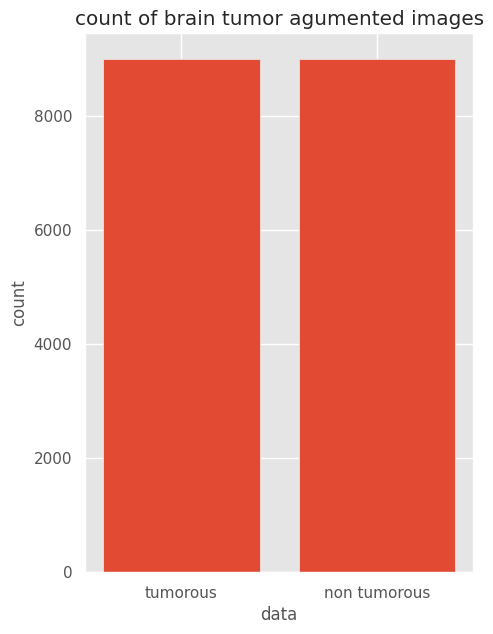

In [21]:
data={"tumorous":yes_number, "non tumorous": no_number}
typx= data.keys()
values = data.values()
plt.figure(figsize=(5,7))

plt.bar(typx,values)
plt.xlabel("data")
plt.ylabel("count")
plt.title("count of brain tumor agumented images")
plt.show()

## data preprocessing

In [22]:
# Convert BGR TO GRAY
# GaussianBlur
# Threshold
# Erode
# Dilate
# Find Contours

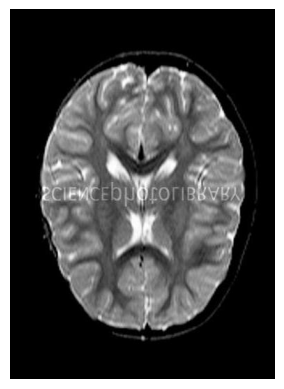

In [23]:
img = plt.imread('/content/no/N_10.jpg')
plt.imshow(img)
plt.axis("off")
plt.show()

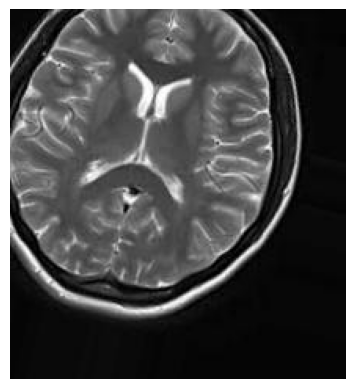

In [25]:
img = plt.imread('/content/augmented_data/no/aug_N_1000_0_8167.jpg')
plt.imshow(img)
plt.axis("off")
plt.show()

In [26]:
# emove the black noise (the empty space around the skull)
import imutils
def crop_brain_tumor(image, plot=False):
  gray= cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  gray = cv2.GaussianBlur(gray,(5,5),0) # remove noise

  # Isolating the Brain
  thes = cv2.threshold(gray, 45,255, cv2.THRESH_BINARY)[1] # Any pixel darker than 45 turned to 0 (black) ,anything brighter is turned to 255

  # erode: perform erosion--> A white pixel only stays white if all the pixels under that kernel are white.
  # If even one is black, the pixel turns black.to remove white noise
  thes = cv2.erode(thes, None, iterations=2)

  # dilate: perform Dilation A black pixel turns white if at least one pixel under the kernel is white
  thes = cv2.dilate(thes,None, iterations=2)

  # Finding the Contours
  cuts = cv2.findContours(thes.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
  # cv2.RETR_EXTERNAL: Only retrieves the outermost outlines (the skull/brain boundary)
  # cv2.CHAIN_APPROX_SIMPLE : Removes redundant points (like points along a straight line)
  cuts = imutils.grab_contours(cuts)
  if not cuts:
        return image
  c = max(cuts, key=cv2.contourArea) # get the max area which is the brain

  extLeft = tuple(c[c[:,:,0].argmin()][0])
  extRight = tuple(c[c[:,:,0].argmax()][0])
  extTop = tuple(c[c[:,:,1].argmin()][0])
  extBot = tuple(c[c[:,:,1].argmax()][0])

 # cutting
  new_image = image[extTop[1]:extBot[1], extLeft[0]:extRight[0]]

  if plot:
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)) # Convert BGR to RGB for correct colors in plot
        plt.title('Original Image')
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(cv2.cvtColor(new_image, cv2.COLOR_BGR2RGB))
        plt.title('Cropped Image')
        plt.axis("off")
        plt.show()
  return new_image

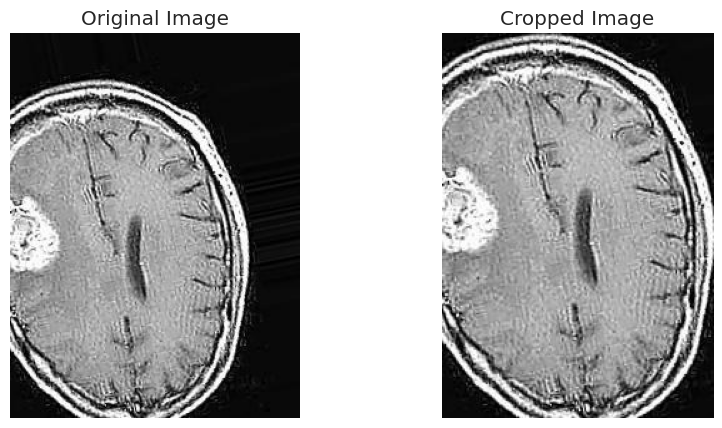

array([[[9, 9, 9],
        [9, 9, 9],
        [9, 9, 9],
        ...,
        [9, 9, 9],
        [9, 9, 9],
        [9, 9, 9]],

       [[9, 9, 9],
        [9, 9, 9],
        [9, 9, 9],
        ...,
        [9, 9, 9],
        [9, 9, 9],
        [9, 9, 9]],

       [[9, 9, 9],
        [9, 9, 9],
        [9, 9, 9],
        ...,
        [9, 9, 9],
        [9, 9, 9],
        [9, 9, 9]],

       ...,

       [[9, 9, 9],
        [9, 9, 9],
        [9, 9, 9],
        ...,
        [8, 8, 8],
        [7, 7, 7],
        [7, 7, 7]],

       [[9, 9, 9],
        [9, 9, 9],
        [9, 9, 9],
        ...,
        [8, 8, 8],
        [8, 8, 8],
        [7, 7, 7]],

       [[9, 9, 9],
        [9, 9, 9],
        [9, 9, 9],
        ...,
        [8, 8, 8],
        [8, 8, 8],
        [8, 8, 8]]], dtype=uint8)
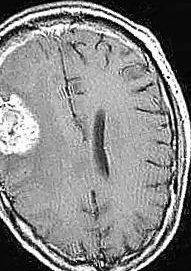

In [27]:
img = cv2.imread('/content/augmented_data/yes/aug_Y_1000_0_8300.jpg')
crop_brain_tumor(img, True)

In [28]:
folder1 = '/content/augmented_data/no'
folder2 = '/content/augmented_data/yes'

for filename in os.listdir(folder1):
    img = cv2.imread(os.path.join(folder1, filename))
    img = crop_brain_tumor(img, False)
    cv2.imwrite(os.path.join(folder1, filename), img)
for filename in os.listdir(folder2):
    img = cv2.imread(os.path.join(folder2, filename))
    img = crop_brain_tumor(img, False)
    cv2.imwrite(os.path.join(folder2, filename), img)

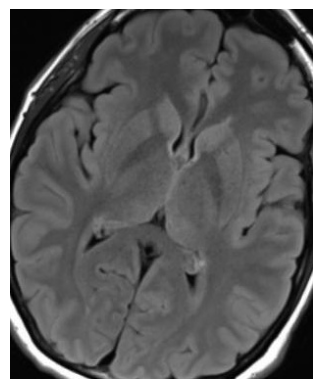

In [29]:
img = plt.imread('/content/augmented_data/no/aug_N_1004_0_7390.jpg')
plt.imshow(img)
plt.axis("off")
plt.show()

## image loading

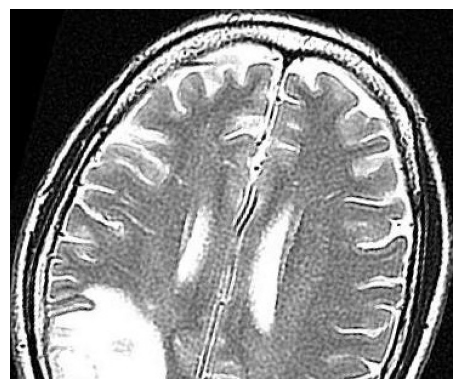

In [31]:
img = plt.imread('/content/augmented_data/yes/aug_Y_1014_0_4022.jpg')
plt.imshow(img)
plt.axis('off')
plt.show()

In [32]:
def load_data(dir_list, image_size):
  x=[]
  y=[]
  image_width, image_height= image_size

  for directory in dir_list:
    for filename in os.listdir(directory):
      image = cv2.imread(directory+'/'+filename)
      image = cv2.resize(image, dsize=(image_width, image_height), interpolation=cv2.INTER_CUBIC)
      image = (image/255.00).astype('float16')
      x.append(image)
      if directory[-3:]=='yes':
        y.append(1)
      else:
        y.append(0)
  x = np.array(x, dtype='float16')
  y = np.array(y)
  x,y = shuffle(x,y)
  print(f"Number of example is : {len(x)}")
  print(f"X SHAPE is : {x.shape}")
  print(f"y SHAPE is : {y.shape}")
  return x,y

In [33]:
augmented_path = 'augmented_data/'
augmeneted_yes = augmented_path + 'yes'
augmeneted_no = augmented_path + 'no'

IMAGE_WIDTH, IMAGE_HEIGHT = (128,128)

x,y = load_data([augmeneted_yes, augmeneted_no], (IMAGE_WIDTH, IMAGE_HEIGHT))

Number of example is : 17999
X SHAPE is : (17999, 128, 128, 3)
y SHAPE is : (17999,)


## data splitting

In [34]:
if not os.path.isdir('tumorous_and_nontumorous'):
  base_dir = 'tumorous_and_nontumorous'
  os.mkdir(base_dir)

In [35]:
if not os.path.isdir('tumorous_and_nontumorous/train'):
    train_dir = os.path.join(base_dir , 'train')
    os.mkdir(train_dir)
if not os.path.isdir('tumorous_and_nontumorous/test'):
    test_dir = os.path.join(base_dir , 'test')
    os.mkdir(test_dir)
if not os.path.isdir('tumorous_and_nontumorous/valid'):
    valid_dir = os.path.join(base_dir , 'valid')
    os.mkdir(valid_dir)

In [36]:
if not os.path.isdir('tumorous_and_nontumorous/train/tumorous'):
    infected_train_dir = os.path.join(train_dir, 'tumorous')
    os.mkdir(infected_train_dir)
if not os.path.isdir('tumorous_and_nontumorous/test/tumorous'):
    infected_test_dir = os.path.join(test_dir, 'tumorous')
    os.mkdir(infected_test_dir)
if not os.path.isdir('tumorous_and_nontumorous/valid/tumorous'):
    infected_valid_dir = os.path.join(valid_dir, 'tumorous')
    os.mkdir(infected_valid_dir)

In [37]:
if not os.path.isdir('tumorous_and_nontumorous/train/nontumorous'):
    healthy_train_dir = os.path.join(train_dir, 'nontumorous')
    os.mkdir(healthy_train_dir)
if not os.path.isdir('tumorous_and_nontumorous/test/nontumorous'):
    healthy_test_dir = os.path.join(test_dir, 'nontumorous')
    os.mkdir(healthy_test_dir)
if not os.path.isdir('tumorous_and_nontumorous/valid/nontumorous'):
    healthy_valid_dir = os.path.join(valid_dir, 'nontumorous')
    os.mkdir(healthy_valid_dir)

In [38]:
original_dataset_tumorours = os.path.join('augmented_data','yes/')
original_dataset_nontumorours = os.path.join('augmented_data','no/')

In [39]:
len(os.listdir('augmented_data/yes/'))

8999

In [40]:
len(os.listdir('augmented_data/no/'))

9000

In [41]:
files = os.listdir('augmented_data/yes/')
fnames = []
for i in range(0,7200):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_tumorours, fname)
    dst = os.path.join(infected_train_dir, fname)
    shutil.copyfile(src, dst)

In [42]:
files = os.listdir('augmented_data/yes/')
fnames = []
for i in range(7200,8100):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_tumorours, fname)
    dst = os.path.join(infected_test_dir, fname)
    shutil.copyfile(src, dst)

In [43]:
files = os.listdir('augmented_data/yes/')
fnames = []
for i in range(8100,8996):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_tumorours, fname)
    dst = os.path.join(infected_valid_dir, fname)
    shutil.copyfile(src, dst)

In [44]:
files = os.listdir('augmented_data/no/')
fnames = []
for i in range(0,7200):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_nontumorours, fname)
    dst = os.path.join(healthy_train_dir, fname)
    shutil.copyfile(src, dst)

In [45]:
files = os.listdir('augmented_data/no/')
fnames = []
for i in range(7200,8100):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_nontumorours, fname)
    dst = os.path.join(healthy_test_dir, fname)
    shutil.copyfile(src, dst)

In [46]:
files = os.listdir('augmented_data/no/')
fnames = []
for i in range(8100,8997):
    fnames.append(files[i])
for fname in fnames:
    src = os.path.join(original_dataset_nontumorours, fname)
    dst = os.path.join(healthy_valid_dir, fname)
    shutil.copyfile(src, dst)

In [47]:
len(os.listdir('/content/tumorous_and_nontumorous/train/nontumorous'))

7200

## Building model

In [48]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                  horizontal_flip=0.4,
                  vertical_flip=0.4,
                  rotation_range=40,
                  shear_range=0.2,
                  width_shift_range=0.4,
                  height_shift_range=0.4,
                  fill_mode='nearest')
test_data_gen = ImageDataGenerator(rescale=1.0/255)
valid_data_gen = ImageDataGenerator(rescale=1.0/255)

In [49]:
train_generator = train_datagen.flow_from_directory('/content/tumorous_and_nontumorous/train/',
                                                    batch_size=32,
                                                    target_size=(224,224),
                                                    class_mode='categorical',
                                                    shuffle=True, seed = 42, color_mode = 'rgb')

Found 14400 images belonging to 2 classes.


In [50]:
test_generator = test_data_gen.flow_from_directory(
    '/content/tumorous_and_nontumorous/test/',
    batch_size=32, target_size=(224,224),
    class_mode='categorical', shuffle=False, color_mode='rgb')

Found 1800 images belonging to 2 classes.


In [51]:
valid_generator = valid_data_gen.flow_from_directory(
    '/content/tumorous_and_nontumorous/valid/',
    batch_size=32, target_size=(224,224),
    class_mode='categorical', shuffle=False, color_mode='rgb')

Found 1793 images belonging to 2 classes.


In [52]:
class_labels = train_generator.class_indices
class_name = {value: key for (key,value) in class_labels.items()}

In [53]:
class_name

{0: 'nontumorous', 1: 'tumorous'}

In [54]:
base_model = VGG19(input_shape = (224,224,3), include_top=False, weights='imagenet')

for layer in base_model.layers:
    layer.trainable=False

x=base_model.output
flat = Flatten()(x)

class_1 = Dense(4608, activation = 'relu')(flat)
drop_out = Dropout(0.2)(class_1)
class_2 = Dense(1152, activation = 'relu')(drop_out)
output = Dense(2, activation = 'softmax')(class_2)

model_01 = Model(base_model.input, output)
model_01.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4608)           │   115,610,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4608)           │             

 Total params: 140,946,370 (537.67 MB)

 Trainable params: 120,921,986 (461.28 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [55]:
# callback
es = EarlyStopping(monitor='val_loss', mode='min', patience=4,
                   restore_best_weights=True, verbose=1)
cp = ModelCheckpoint('best_model.keras', monitor='val_loss',
                     save_best_only=True, verbose=1)
lrr = ReduceLROnPlateau(monitor='val_accuracy', patience=3, factor=0.5,
                        min_lr=0.0001, mode='max', verbose=1)

In [56]:
sgd = SGD(learning_rate=0.0001, momentum = 0.9, nesterov = True)
model_01.compile(loss='categorical_crossentropy', optimizer = sgd, metrics=['accuracy'])

In [57]:
history_01 = model_01.fit(train_generator, steps_per_epoch=10, epochs = 10, callbacks=[es,cp,lrr], validation_data=valid_generator)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step - accuracy: 0.5892 - loss: 0.6999
Epoch 1: val_loss improved from None to 0.78085, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.5781 - loss: 0.6923 - val_accuracy: 0.4992 - val_loss: 0.7809 - learning_rate: 1.0000e-04
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 576ms/step - accuracy: 0.4937 - loss: 0.7803
Epoch 2: val_loss improved from 0.78085 to 0.70303, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.5125 - loss: 0.7443 - val_accuracy: 0.5114 - val_loss: 0.7030 - learning_rate: 1.0000e-04
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.5392 - loss: 0.7213
Epoch 3: val_loss improved from 0.70303 to 0.67130, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accurac

In [59]:
if not os.path.isdir('model_weights/'):
    os.mkdir('model_weights/')
model_01.save_weights(filepath="model_weights/vgg19_model_01.weights.h5", overwrite=True)

#if not os.path.isdir('models/'):
    #os.mkdir('models/')

# Save the WHOLE model (architecture + weights + optimizer state)
#model_01.save("models/vgg19_full_model.keras")

In [61]:
model_01.load_weights("/content/model_weights/vgg19_model_01.weights.h5")
vgg_val_eval_01 = model_01.evaluate(valid_generator)
vgg_test_eval_01 = model_01.evaluate(test_generator)

57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 171ms/step - accuracy: 0.6799 - loss: 0.6065
57/57 ━━━━━━━━━━━━━━━━━━━━ 12s 213ms/step - accuracy: 0.6917 - loss: 0.6053


In [62]:
print(f'Validation Loss: {vgg_val_eval_01[0]}')
print(f'Validation Acc: {vgg_val_eval_01[1]}')
print(f'Testing Loss: {vgg_test_eval_01[0]}')
print(f'Testing Acc: {vgg_test_eval_01[1]}')

Validation Loss: 0.6065018177032471
Validation Acc: 0.6798661351203918
Testing Loss: 0.605299711227417
Testing Acc: 0.6916666626930237


In [63]:
filenames = test_generator.filenames
nb_sample = len(filenames)

vgg_prediction_01 = model_01.predict(test_generator, steps=nb_sample, verbose = 1)
y_pred = np.argmax(vgg_prediction_01, axis=1)

1800/1800 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step   


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [64]:
base_model = VGG19(include_top=False, input_shape=(224,224,3))
base_model_layer_names = [layer.name for layer in base_model.layers]

x=base_model.output
flat = GlobalAveragePooling2D()(x)

class_1 = Dense(1024, activation = 'relu')(flat)
drop_out = Dropout(0.4)(class_1)
class_2 = Dense(512, activation='relu')(drop_out)
drop_out2 = Dropout(0.3)(class_2)
output = Dense(2, activation = 'softmax')(drop_out2)

model_02 = Model(base_model.inputs, output)
# model_02.load_weights('/content/model_weights/vgg19_model_01.weights.h5')

set_trainable=False
for layer in base_model.layers:
    if layer.name in ['block5_conv4','block5_conv3']:
        set_trainable=True
    if set_trainable:
        layer.trainable=True
    else:
        layer.trainable=False

print(model_02.summary())

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 21,075,522 (80.40 MB)

 Trainable params: 5,770,754 (22.01 MB)

 Non-trainable params: 15,304,768 (58.38 MB)

None


In [65]:
sgd = SGD(learning_rate=0.01, momentum = 0.9, nesterov = True)
model_02.compile(loss='categorical_crossentropy', optimizer = sgd, metrics=['accuracy'])

In [66]:
history_02 = model_02.fit(train_generator, epochs =20, callbacks=[es,cp,lrr], validation_data=valid_generator)

Epoch 1/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 536ms/step - accuracy: 0.7042 - loss: 0.5451
Epoch 1: val_loss improved from 0.60650 to 0.16539, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
450/450 ━━━━━━━━━━━━━━━━━━━━ 261s 565ms/step - accuracy: 0.7948 - loss: 0.4278 - val_accuracy: 0.9381 - val_loss: 0.1654 - learning_rate: 0.0100
Epoch 2/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step - accuracy: 0.8773 - loss: 0.2871
Epoch 2: val_loss improved from 0.16539 to 0.10708, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
450/450 ━━━━━━━━━━━━━━━━━━━━ 230s 511ms/step - accuracy: 0.8856 - loss: 0.2679 - val_accuracy: 0.9571 - val_loss: 0.1071 - learning_rate: 0.0100
Epoch 3/20
450/450 ━━━━━━━━━━━━━━━━━━━━ 0s 502ms/step - accuracy: 0.9071 - loss: 0.2256
Epoch 3: val_loss improved from 0.10708 to 0.10131, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
450/450 ━━━━━━━━━━━━━━━━━━━━ 236s 5

In [67]:
if not os.path.isdir('model_weights/'):
    os.mkdir('model_weights/')
model_02.save_weights(filepath="model_weights/vgg19_model_02.weights.h5", overwrite=True)

57/57 ━━━━━━━━━━━━━━━━━━━━ 11s 193ms/step - accuracy: 0.9939 - loss: 0.0211
Test accuracy: 0.9939
57/57 ━━━━━━━━━━━━━━━━━━━━ 12s 188ms/step
              precision    recall  f1-score   support

 nontumorous       0.99      0.99      0.99       900
    tumorous       0.99      0.99      0.99       900

    accuracy                           0.99      1800
   macro avg       0.99      0.99      0.99      1800
weighted avg       0.99      0.99      0.99      1800

AUC-ROC: 0.999579012345679


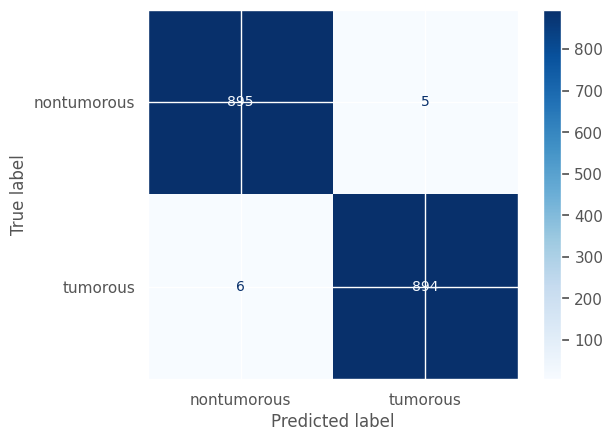

In [68]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

test_loss, test_acc = model_02.evaluate(test_generator)
print(f"Test accuracy: {test_acc:.4f}")

probs = model_02.predict(test_generator, verbose=1)
y_pred = np.argmax(probs, axis=1)
y_true = test_generator.classes
labels = list(test_generator.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=labels))
print("AUC-ROC:", roc_auc_score(y_true, probs[:, 1]))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='Blues')
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [69]:
model_02.load_weights("/content/model_weights/vgg19_model_02.weights.h5")
vgg_val_eval_02 = model_02.evaluate(valid_generator)
vgg_test_eval_02 = model_02.evaluate(test_generator)

57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 174ms/step - accuracy: 0.9905 - loss: 0.0246
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 175ms/step - accuracy: 0.9939 - loss: 0.0211


In [ ]:
model_02.save('model_02.keras')